# Oracle BO on Branin — initialization, best evaluations, and final evaluations

This diagnostic studies whether increasing ambient dimension makes Oracle BO spend more evaluations exploring because the projected initial design concentrates near the center of the effective domain.

For each $d$, the plot overlays:

- all projected initial points $z_{\rm init}=A^\top x_{\rm init}$;
- the best `N_BEST = 5` post-initialization Oracle evaluations from each run;
- the final `FINAL_FEW = 2` chronological Oracle evaluations from each run;
- the normalized Branin contour on $[-1,1]^2$;
- the effective feasible-domain boundary $\|z\|_2=1$;
- the feasible Branin global minima;
- radius-$R_\epsilon$ neighborhoods around each feasible global minimum.

The clustering percentage is calculated using the best `N_BEST` points.


## 1. Setup and data loading

Set `SAVE_FIGURES = True` to save every generated plot under `DATA_DIR/figures/oracle_dim_diagnostics/`.


In [8]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data_long3")
CACHE_FILE = DATA_DIR / "cache" / "processed_records.pkl"
PROBLEM_DIR = DATA_DIR / "problems"

N_BEST = 5
FINAL_FEW = 2
R_EPSILON = 0.01

# Figure saving
SAVE_FIGURES = False
FIGURE_DIR = DATA_DIR / "figures" / "diagnostics_oracle_dim"
FIGURE_DPI = 200

if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)


In [9]:
if not CACHE_FILE.exists():
    raise FileNotFoundError(
        f"Cache not found: {CACHE_FILE}. Run the main analysis notebook first."
    )

with open(CACHE_FILE, "rb") as f:
    records = pickle.load(f)

for r in records:
    if r.get("embedding") == "inclusion":
        r["embedding"] = "aae"

oracle_branin = [
    r for r in records
    if r["objective_name"] == "branin"
    and r["solver"] == "bo_oracle"
]

print("Oracle Branin runs:", len(oracle_branin))
print("Dimensions:", sorted({r["d"] for r in oracle_branin}))
print("N_BEST:", N_BEST)
print("FINAL_FEW:", FINAL_FEW)
print("R_EPSILON:", R_EPSILON)

Oracle Branin runs: 1680
Dimensions: [2, 5, 10, 20]
N_BEST: 5
FINAL_FEW: 2
R_EPSILON: 0.01


## 2. Normalized Branin and its feasible global minima

The normalized coordinates are

$$
u=2.5+7.5z_1,\qquad
v=7.5+7.5z_2.
$$

Hence the native Branin domain $[-5,10]\times[0,15]$ maps to $[-1,1]^2$.

The native global minimizers are transformed into normalized $z$ coordinates below. Only minima satisfying $\|z\|_2\leq1$ are feasible for the embedded unit-ball problem.


In [10]:
def branin_native(u, v):
    a = 1.0
    b = 5.1 / (4.0 * np.pi**2)
    c = 5.0 / np.pi
    r = 6.0
    s = 10.0
    t = 1.0 / (8.0 * np.pi)

    return (
        a * (v - b * u**2 + c * u - r)**2
        + s * (1.0 - t) * np.cos(u)
        + s
    )


def branin_normalized_grid(z1, z2):
    u = 2.5 + 7.5 * z1
    v = 7.5 + 7.5 * z2
    return branin_native(u, v)


native_minima = np.array([
    [-np.pi, 12.275],
    [ np.pi,  2.275],
    [3 * np.pi, 2.475],
])

normalized_minima = np.column_stack([
    (native_minima[:, 0] - 2.5) / 7.5,
    (native_minima[:, 1] - 7.5) / 7.5,
])

feasible_mask = np.linalg.norm(normalized_minima, axis=1) <= 1.0 + 1e-12
feasible_minima = normalized_minima[feasible_mask]

print("Normalized Branin minima:")
print(normalized_minima)
print("Feasible minima in unit disk:")
print(feasible_minima)


Normalized Branin minima:
[[-0.75221235  0.63666667]
 [ 0.08554569 -0.69666667]
 [ 0.92330373 -0.67      ]]
Feasible minima in unit disk:
[[-0.75221235  0.63666667]
 [ 0.08554569 -0.69666667]]


## 3. Initial, best, and final Oracle evaluation locations by ambient dimension

For each Oracle run:

- **best points** are the `N_BEST` post-initialization evaluations with the smallest Branin objective values;
- **final points** are the chronologically last `FINAL_FEW` post-initialization evaluations.

A best point is counted as clustered around a global minimum if its distance from at least one feasible global minimizer is at most

$$
R_\epsilon=0.05.
$$

The reported clustering percentage is

$$
100\times
\frac{\#\{\text{best points within }R_\epsilon\text{ of a feasible global minimum}\}}
{\#\{\text{best points}\}}.
$$


d=2: 2100/2100 best points (100.0%) within R_EPSILON=0.01 of a feasible global minimum


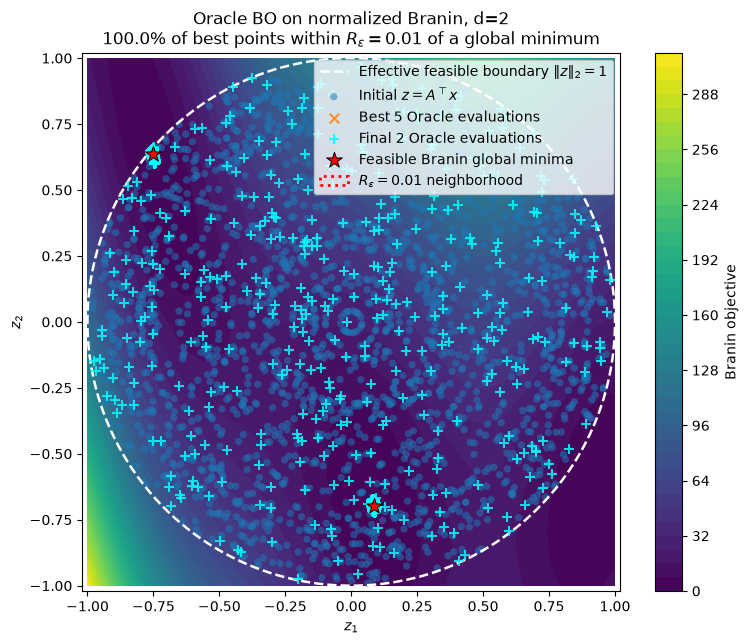

d=5: 2083/2100 best points (99.2%) within R_EPSILON=0.01 of a feasible global minimum


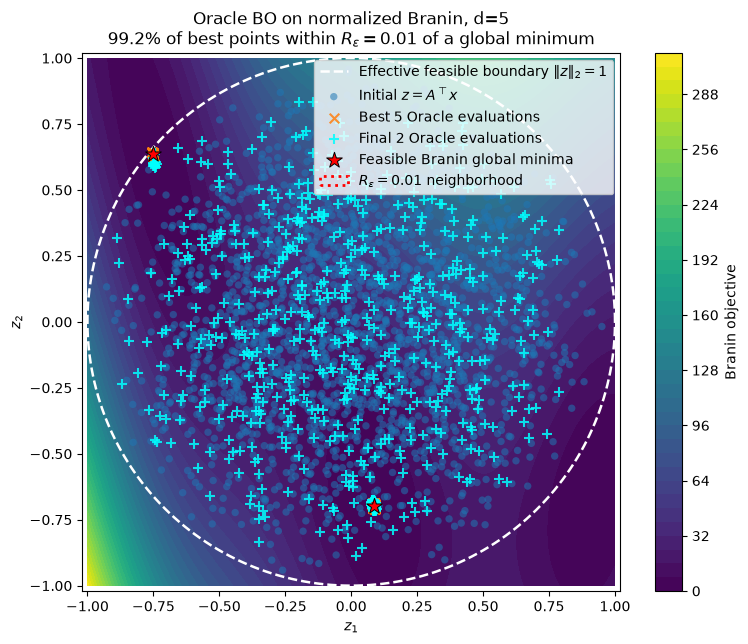

d=10: 1757/2100 best points (83.7%) within R_EPSILON=0.01 of a feasible global minimum


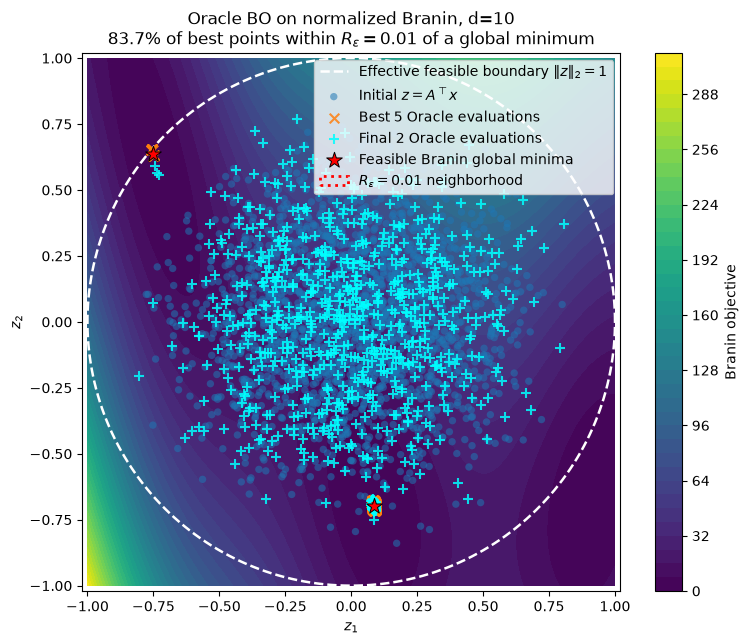

d=20: 294/2100 best points (14.0%) within R_EPSILON=0.01 of a feasible global minimum


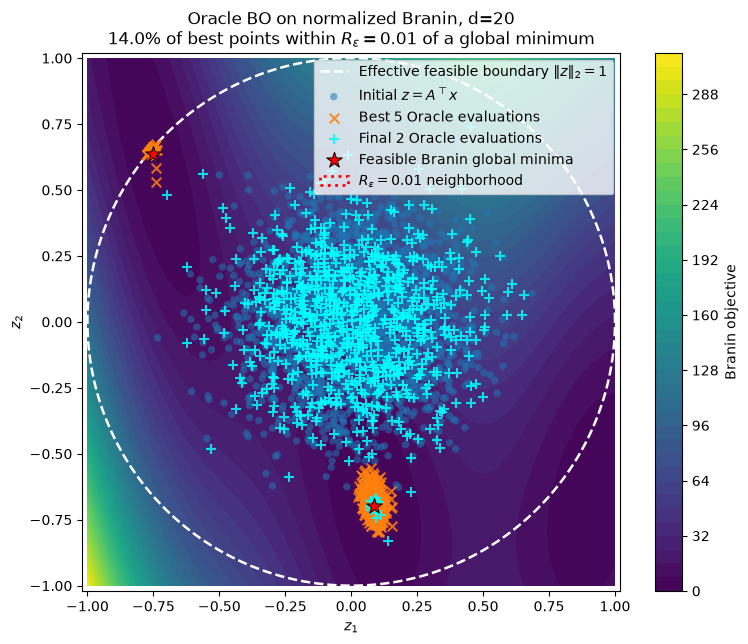

,d,n_runs,n_best_per_run,n_final_per_run,n_selected_best_points,n_best_within_radius,percentage_best_within_radius
0,2,420,5,2,2100,2100,100.000000
1,5,420,5,2,2100,2083,99.190476
2,10,420,5,2,2100,1757,83.666667
3,20,420,5,2,2100,294,14.000000


In [11]:
# Contour grid on normalized [-1,1]^2.
grid = np.linspace(-1.0, 1.0, 350)
Z1, Z2 = np.meshgrid(grid, grid)
BRANIN = branin_normalized_grid(Z1, Z2)

theta = np.linspace(0, 2 * np.pi, 500)
circle_x = np.cos(theta)
circle_y = np.sin(theta)

clustering_rows = []

for d in sorted({r["d"] for r in oracle_branin}):
    runs_d = [r for r in oracle_branin if r["d"] == d]

    # ------------------------------------------------------------
    # Initial points.
    # ------------------------------------------------------------
    z_init_sets = []
    seen_init = set()

    for r in runs_d:
        key = (r["embedding"], r["A_index"], r["init_index"])
        if key in seen_init:
            continue
        seen_init.add(key)

        problem_path = PROBLEM_DIR / f"{r['problem_id']}.npz"

        if not problem_path.exists():
            raise FileNotFoundError(f"Missing problem file: {problem_path}")

        with np.load(problem_path) as problem_data:
            X_init = np.asarray(problem_data["X_init"], dtype=float)
            A = np.asarray(problem_data["A"], dtype=float)

        z_init_sets.append(X_init @ A)

    Z_init = np.vstack(z_init_sets)

    # ------------------------------------------------------------
    # Best N_BEST and final FINAL_FEW Oracle evaluations per run.
    # ------------------------------------------------------------
    z_best_sets = []
    z_final_sets = []

    for r in runs_d:
        run_path = DATA_DIR / "runs" / f"{r['run_id']}.npz"

        if not run_path.exists():
            raise FileNotFoundError(f"Missing run file: {run_path}")

        with np.load(run_path) as run_data:
            X_new = np.asarray(run_data["X_new"], dtype=float)
            y_new = np.asarray(run_data["y_new"], dtype=float)

        A = np.asarray(r["A"], dtype=float)

        # Best N_BEST by objective value.
        n_best = min(N_BEST, len(X_new))
        best_idx = np.argsort(y_new)[:n_best]
        Z_best = X_new[best_idx] @ A
        z_best_sets.append(Z_best)

        # Final FINAL_FEW chronologically.
        n_final = min(FINAL_FEW, len(X_new))
        Z_final = X_new[-n_final:] @ A
        z_final_sets.append(Z_final)

    Z_best_all = np.vstack(z_best_sets)
    Z_final_all = np.vstack(z_final_sets)

    # ------------------------------------------------------------
    # Percentage of best points near either feasible global minimum.
    # ------------------------------------------------------------
    distances = np.linalg.norm(
        Z_best_all[:, None, :] - feasible_minima[None, :, :],
        axis=2,
    )
    nearest_distance = distances.min(axis=1)
    clustered = nearest_distance <= R_EPSILON

    n_selected = len(Z_best_all)
    n_clustered = int(clustered.sum())
    pct_clustered = (
        100.0 * n_clustered / n_selected
        if n_selected else np.nan
    )

    clustering_rows.append({
        "d": d,
        "n_runs": len(runs_d),
        "n_best_per_run": N_BEST,
        "n_final_per_run": FINAL_FEW,
        "n_selected_best_points": n_selected,
        "n_best_within_radius": n_clustered,
        "percentage_best_within_radius": pct_clustered,
    })

    print(
        f"d={d}: {n_clustered}/{n_selected} best points "
        f"({pct_clustered:.1f}%) within R_EPSILON={R_EPSILON} "
        "of a feasible global minimum"
    )

    # ------------------------------------------------------------
    # Plot.
    # ------------------------------------------------------------
    plt.figure(figsize=(8, 6.5))

    contour = plt.contourf(
        Z1,
        Z2,
        BRANIN,
        levels=40,
        cmap="viridis",
    )
    plt.colorbar(contour, label="Branin objective")

    # Effective feasible-domain boundary.
    plt.plot(
        circle_x,
        circle_y,
        color="white",
        linestyle="--",
        linewidth=1.8,
        label=r"Effective feasible boundary $\|z\|_2=1$",
    )

    # Initial projected points.
    plt.scatter(
        Z_init[:, 0],
        Z_init[:, 1],
        s=28,
        alpha=0.55,
        color="tab:blue",
        label=r"Initial $z=A^\top x$",
        edgecolors="none",
    )

    # Best Oracle evaluations.
    plt.scatter(
        Z_best_all[:, 0],
        Z_best_all[:, 1],
        s=48,
        alpha=0.85,
        marker="x",
        color="tab:orange",
        label=f"Best {N_BEST} Oracle evaluations",
        zorder=4,
    )

    # Final chronological Oracle evaluations.
    plt.scatter(
        Z_final_all[:, 0],
        Z_final_all[:, 1],
        s=48,
        alpha=0.85,
        marker="+",
        color="cyan",
        label=f"Final {FINAL_FEW} Oracle evaluations",
        zorder=5,
    )

    # Feasible Branin global minima.
    plt.scatter(
        feasible_minima[:, 0],
        feasible_minima[:, 1],
        s=140,
        marker="*",
        color="red",
        edgecolors="black",
        linewidths=0.7,
        label="Feasible Branin global minima",
        zorder=7,
    )

    # R_EPSILON neighborhoods.
    for j, minimum in enumerate(feasible_minima):
        eps_circle = plt.Circle(
            minimum,
            R_EPSILON,
            fill=False,
            color="red",
            linestyle=":",
            linewidth=2,
            label=(
                rf"$R_\epsilon={R_EPSILON}$ neighborhood"
                if j == 0 else None
            ),
            zorder=6,
        )
        plt.gca().add_patch(eps_circle)

    plt.xlabel("$z_1$")
    plt.ylabel("$z_2$")
    plt.title(
        f"Oracle BO on normalized Branin, d={d}\n"
        f"{pct_clustered:.1f}% of best points within "
        rf"$R_\epsilon={R_EPSILON}$ of a global minimum"
    )
    plt.xlim(-1.02, 1.02)
    plt.ylim(-1.02, 1.02)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.tight_layout()

    if SAVE_FIGURES:
        filename = (
            f"oracle_branin_aggregate__d{d}"
            f"__best{N_BEST}"
            f"__final{FINAL_FEW}"
            f"__reps{R_EPSILON:g}.png"
        )
        plt.savefig(
            FIGURE_DIR / filename,
            dpi=FIGURE_DPI,
            bbox_inches="tight",
        )

    plt.show()


clustering_df = pd.DataFrame(clustering_rows)
display(clustering_df)


## 4. Oracle evaluation trajectory for one initial design

This section follows one Oracle BO run for each ambient dimension $d$. We fix `TRAJECTORY_INIT_INDEX = 0` and use the axis-aligned embedding (AAE) for every $d$.

| $d$ | Initial design | Embedding |
|---:|---|---|
| 2 | $X_{\rm init}^{(2,0)}$ | $A_{\rm AAE}(2)$ |
| 5 | $X_{\rm init}^{(5,0)}$ | $A_{\rm AAE}(5)$ |
| 10 | $X_{\rm init}^{(10,0)}$ | $A_{\rm AAE}(10)$ |
| 20 | $X_{\rm init}^{(20,0)}$ | $A_{\rm AAE}(20)$ |

The same **initialization index** is used across dimensions, but the actual $X_{\rm init}$ sets differ because their generation depends on $d$.

Each plot shows the projected initial points $A^\top X_{\rm init}$ and all subsequent Oracle evaluations $A^\top x_{\rm next}$. The latter are colored by total evaluation number. Feasible Branin global minima and the effective unit-disk boundary are shown for reference.

If $n_{\rm init}=5$, the first BO-selected point corresponds to evaluation 6.

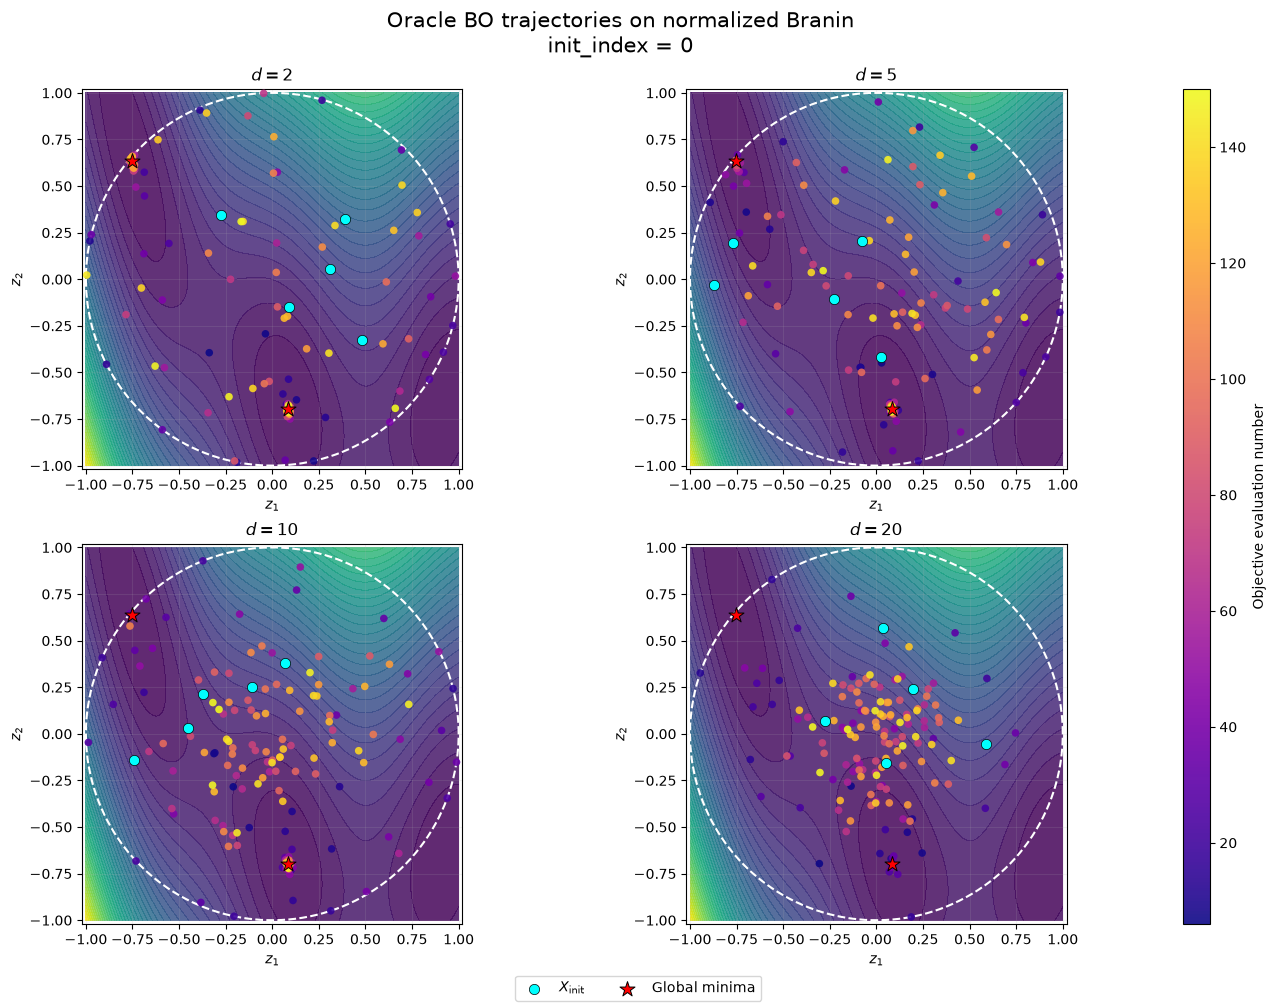

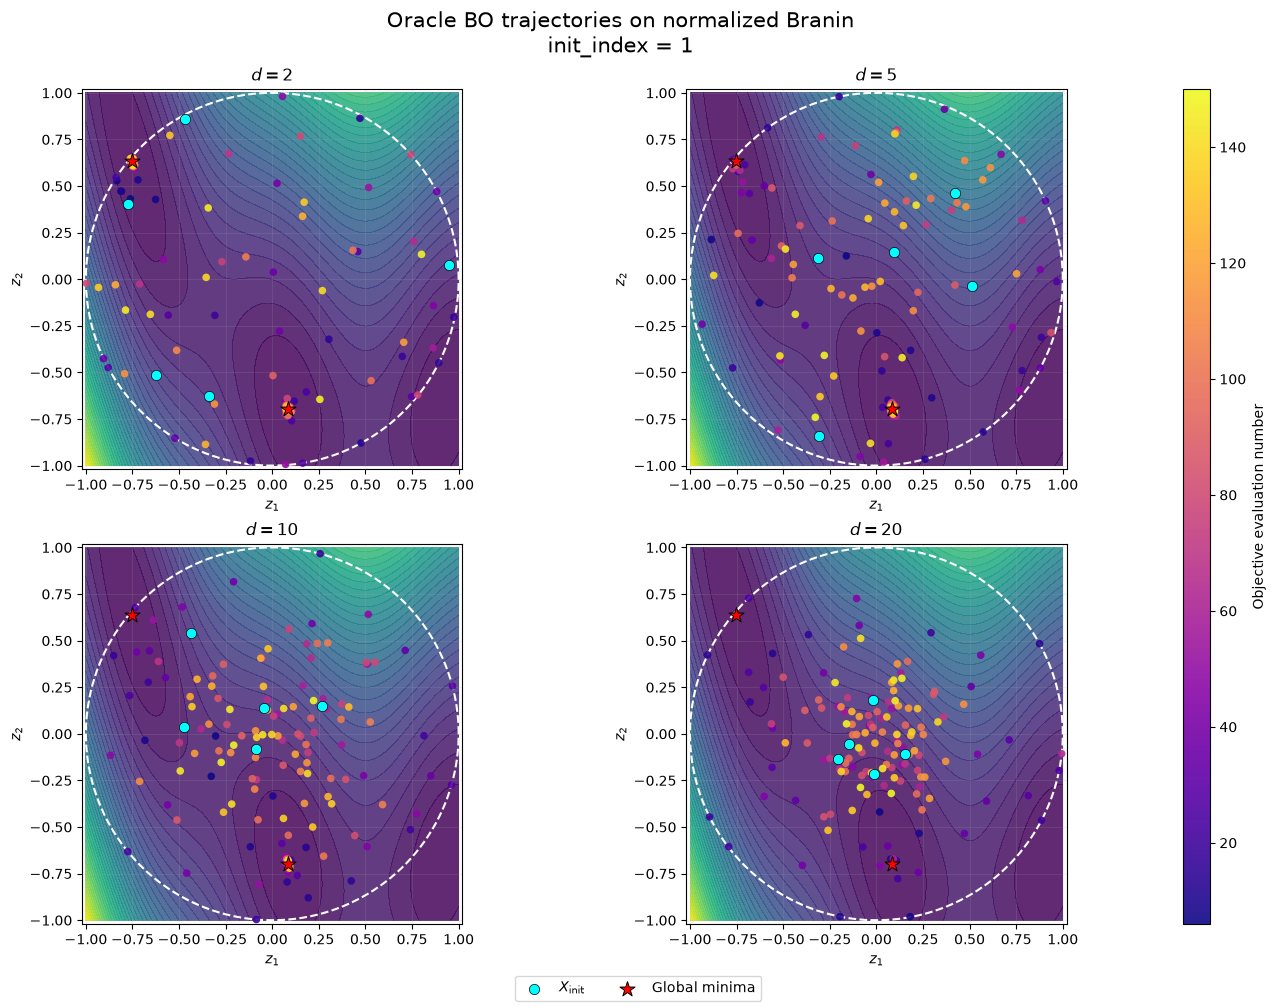

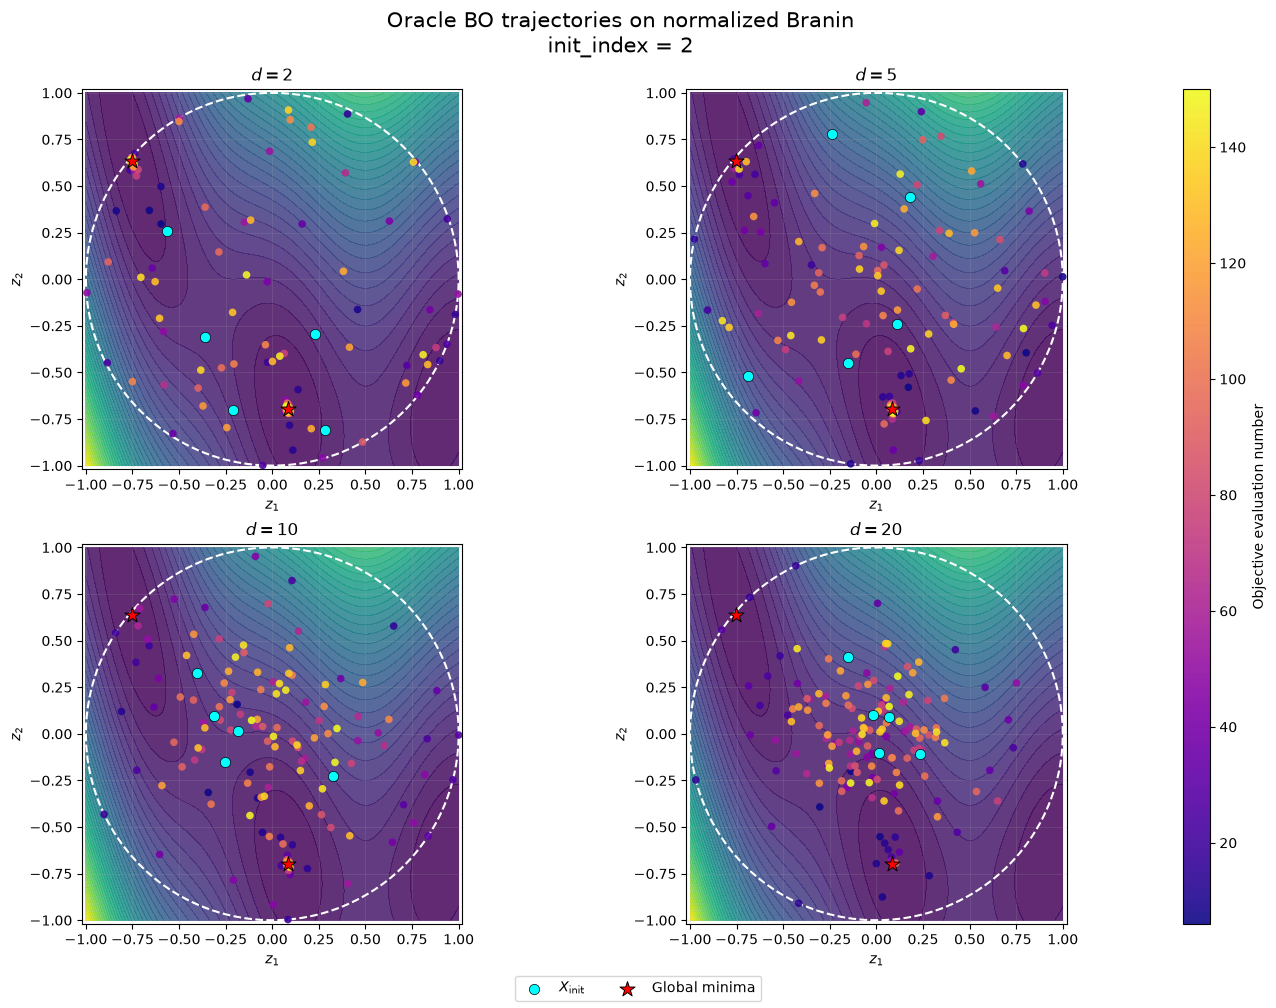

In [12]:
TRAJECTORY_INIT_INDICES = [0, 1, 2]

dimensions = [2, 5, 10, 20]

for trajectory_init_index in TRAJECTORY_INIT_INDICES:

    # ------------------------------------------------------------
    # Layout:
    # 2 x 2 plots + dedicated colorbar column
    # ------------------------------------------------------------
    fig = plt.figure(
        figsize=(13, 10),
        constrained_layout=True,
    )

    gs = fig.add_gridspec(
        2,
        3,
        width_ratios=[1, 1, 0.045],
    )

    axes = np.array([
        fig.add_subplot(gs[0, 0]),
        fig.add_subplot(gs[0, 1]),
        fig.add_subplot(gs[1, 0]),
        fig.add_subplot(gs[1, 1]),
    ])

    cax = fig.add_subplot(gs[:, 2])

    trajectory_mappable = None

    # ------------------------------------------------------------
    # Plot each dimension
    # ------------------------------------------------------------
    for ax, d in zip(axes, dimensions):

        candidates = [
            r for r in oracle_branin
            if r["d"] == d
            and r["init_index"] == trajectory_init_index
            and r["embedding"] == "aae"
        ]

        if not candidates:
            ax.set_visible(False)
            continue

        r = candidates[0]

        # --------------------------------------------------------
        # Load X_init and A
        # --------------------------------------------------------
        problem_path = (
            PROBLEM_DIR
            / f"{r['problem_id']}.npz"
        )

        if not problem_path.exists():
            raise FileNotFoundError(
                f"Missing problem file: {problem_path}"
            )

        with np.load(problem_path) as problem_data:
            X_init = np.asarray(
                problem_data["X_init"],
                dtype=float,
            )
            A = np.asarray(
                problem_data["A"],
                dtype=float,
            )

        Z_init = X_init @ A
        n_init = len(X_init)

        # --------------------------------------------------------
        # Load all post-initialization Oracle evaluations
        # --------------------------------------------------------
        run_path = (
            DATA_DIR
            / "runs"
            / f"{r['run_id']}.npz"
        )

        if not run_path.exists():
            raise FileNotFoundError(
                f"Missing run file: {run_path}"
            )

        with np.load(run_path) as run_data:
            X_new = np.asarray(
                run_data["X_new"],
                dtype=float,
            )

        Z_new = X_new @ A

        evaluation_numbers = np.arange(
            n_init + 1,
            n_init + len(Z_new) + 1,
        )

        # --------------------------------------------------------
        # Branin contour
        # --------------------------------------------------------
        ax.contourf(
            Z1,
            Z2,
            BRANIN,
            levels=40,
            cmap="viridis",
            alpha=0.85,
        )

        # Effective feasible unit disk
        ax.plot(
            circle_x,
            circle_y,
            color="white",
            linestyle="--",
            linewidth=1.5,
        )

        # --------------------------------------------------------
        # Initial design
        # --------------------------------------------------------
        ax.scatter(
            Z_init[:, 0],
            Z_init[:, 1],
            s=55,
            color="cyan",
            edgecolors="black",
            linewidths=0.5,
            label=r"$X_{\rm init}$",
            zorder=5,
        )

        # --------------------------------------------------------
        # BO trajectory
        # --------------------------------------------------------
        trajectory = ax.scatter(
            Z_new[:, 0],
            Z_new[:, 1],
            c=evaluation_numbers,
            cmap="plasma",
            vmin=n_init + 1,
            vmax=n_init + len(Z_new),
            s=30,
            alpha=0.9,
            edgecolors="none",
            zorder=4,
        )

        if trajectory_mappable is None:
            trajectory_mappable = trajectory

        # --------------------------------------------------------
        # Global minima
        # --------------------------------------------------------
        ax.scatter(
            feasible_minima[:, 0],
            feasible_minima[:, 1],
            s=130,
            marker="*",
            color="red",
            edgecolors="black",
            linewidths=0.7,
            label="Global minima",
            zorder=7,
        )

        # --------------------------------------------------------
        # Formatting
        # --------------------------------------------------------
        ax.set_title(
            rf"$d={d}$",
            fontsize=12,
        )

        ax.set_xlim(-1.02, 1.02)
        ax.set_ylim(-1.02, 1.02)

        ax.set_aspect(
            "equal",
            adjustable="box",
        )

        ax.grid(alpha=0.15)

        ax.set_xlabel("$z_1$")
        ax.set_ylabel("$z_2$")

    # ------------------------------------------------------------
    # Shared colorbar in dedicated column
    # ------------------------------------------------------------
    if trajectory_mappable is not None:
        cbar = fig.colorbar(
            trajectory_mappable,
            cax=cax,
        )

        cbar.set_label(
            "Objective evaluation number"
        )

    # ------------------------------------------------------------
    # Shared legend
    # ------------------------------------------------------------
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="outside lower center",
        ncol=2,
    )

    # ------------------------------------------------------------
    # Overall title
    # ------------------------------------------------------------
    fig.suptitle(
        "Oracle BO trajectories on normalized Branin\n"
        f"init_index = {trajectory_init_index}",
        fontsize=15,
    )

    if SAVE_FIGURES:
        filename = (
            "oracle_branin_trajectory"
            f"__init{trajectory_init_index}.png"
        )
        fig.savefig(
            FIGURE_DIR / filename,
            dpi=FIGURE_DPI,
            bbox_inches="tight",
        )

    plt.show()
